# 综合项目

小兔鲜02：header、footer与主体内容（前端第10天）


## 本日内容与资料

本日把已学过的盒子模型、浮动、定位、伪元素和精灵图用到小兔鲜首页。按照原课顺序，先完成公共头部和页脚，再进入网站入口、新鲜好物面板、生鲜商品面板。

资料来自分享中的 `day10-小兔鲜项目.rar`，包括41页课件和 `01-案例/xtx_pc_client` 项目。此包没有独立XMind或作业文件。笔记以课件的布局分析为主线，用本日配套HTML、CSS说明具体实现。

| 原课部分 | 本日源码对应区域 | 主要练习 |
| --- | --- | --- |
| Header | `.shortcut`、`.header.wrapper` | 通栏与版心、左右浮动、导航、搜索图标、购物车角标 |
| Footer | `.footer .top`、`.footer .bottom` | 宣传服务、精灵图、文字与图标定位、版权信息 |
| 网站入口 `xtx-entry` | `.banner`、`.banner .wrapper` | 图片铺底、分类覆盖、箭头与圆点 |
| 新鲜好物 `xtx-new-goods` | `.goods.wrapper` | 标题栏、四列商品卡片、价格与新品标签 |
| 生鲜商品 `xtx-fresh-goods` | `.shengxian.wrapper` | 右浮动分类、左右内容区、商品列表布局分析 |

> 课件的模块名是布局分析名称，源码使用了另一组类名。看图时先确认区域，再对应选择器，不能把课件中的类名直接当成本项目已有的CSS。

与第09天相比，本日补齐了头部和页脚的文字，调整了三个页脚服务图标，并新增首页主体样式。`base.css`没有变化。

补充：课件展示的是完整目标界面。配套源码已经实现静态轮播入口和新鲜好物卡片，生鲜区右侧仍是空盒子；轮播切换、搜索提交、分类切换也没有实现。后文在对应步骤中说明这些边界。


## 开始前：项目文件与基础样式

在解压得到的 `day10/01-案例/xtx_pc_client/` 中编辑文件，浏览器查看 `index.html`。相对路径以它所在的项目目录为基准。

```text
xtx_pc_client/
├── index.html
├── favicon.ico
├── css/
│   ├── base.css
│   ├── common.css
│   └── index.css
├── images/
│   ├── logo.png
│   └── sprites.png
└── uploads/
    ├── banner_1.png
    ├── new_goods_1.jpg ... new_goods_4.jpg
    ├── fresh_goods_cover.png
    └── 其他项目素材
```

三个样式表各有职责：`base.css`清理默认样式，`common.css`放版心与公共头尾，`index.css`放首页主体。HTML按这个顺序引入。

`index.html`开头原文：

```html
<!DOCTYPE html>
<html lang="en">

<head>
    <meta charset="UTF-8">
    <meta http-equiv="X-UA-Compatible" content="IE=edge">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <!-- meta:desc -->
    <meta name="description" content="小兔鲜儿官网，致力于打造全球最大的食品、生鲜电商购物平台">
    <!-- meta:kw -->
    <meta name="keywords" content="小兔鲜儿,食品,生鲜,服装,家电,电商,购物">
    <title>小兔鲜儿-新鲜、惠民、快捷！</title>
    <!-- link:favicon -->
    <link rel="shortcut icon" href="favicon.ico" type="image/x-icon">
    <!-- 按顺序引入: 外链式样式表后写的生效 -->
    <link rel="stylesheet" href="./css/base.css">
    <link rel="stylesheet" href="./css/common.css">
    <link rel="stylesheet" href="./css/index.css">
</head>

<body>
```

补充：源码注释中的“后写的生效”指符合层叠规则时的覆盖；仍需比较选择器权重等条件。这里保留原来的引入顺序。源码的 `lang="en"` 与中文页面语言不同，实际中文页面应标为 `zh-CN`；以上摘录保留资料原文。


### 统一盒子计算与清除浮动

`css/base.css`原文：

```css
/* 清除默认样式的代码 */
/* 去除常见标签默认的 margin 和 padding */
body,
h1,
h2,
h3,
h4,
h5,
h6,
p,
ul,
ol,
li,
dl,
dt,
dd,
input {
  margin: 0;
  padding: 0;
}

/* 內减模式 */
* {
    box-sizing: border-box;
}

/* 设置网页统一的字体大小、行高、字体系列相关属性 */
body {
  font: 16px/1.5 "Helvetica Neue", Helvetica, Arial, "Microsoft Yahei",
    "Hiragino Sans GB", "Heiti SC", "WenQuanYi Micro Hei", sans-serif;
  color: #333;
}

/* 去除列表默认样式 */
ul,
ol {
  list-style: none;
}

/* 去除默认的倾斜效果 */
em,
i {
  font-style: normal;
}

/* 去除a标签默认下划线，并设置默认文字颜色 */
a {
  text-decoration: none;
  color: #333;
}

/* 设置img的垂直对齐方式为居中对齐，去除img默认下间隙 */
img {
  vertical-align: middle;
}

/* 去除input默认样式 */
input {
  border: none;
  outline: none;
  color: #333;
}

/* 左浮动 */
.fl {
  float: left;
}

/* 右浮动 */
.fr {
  float: right;
}

/* 双伪元素清除法 */
.clearfix::before,
.clearfix::after {
  content: "";
  display: table;
}
.clearfix::after {
  clear: both;
}
```

本日布局依赖以下基础条件：

- 全局使用 `box-sizing: border-box`，声明的宽高包含内边距和边框。
- 清除列表、标题、段落等默认间距，让尺寸以项目CSS为准。
- `img`使用 `vertical-align: middle`，消除行内图片基线造成的下方空隙。
- `.clearfix`通过伪元素清除浮动。商品区的父盒子没有固定高度时，使用它把浮动子元素的高度包含进来。
- 链接默认无下划线，`b`的粗体、`h2`与`h3`的粗细在具体区域单独处理。

补充：`outline: none`会移除输入框默认焦点轮廓，实际页面需要有可见的焦点提示。这里按课堂原文保留，不改成另一套重置样式。

`css/common.css`开头定义通用版心：

```css
/* 各个页面相同的样式表 : 头, 尾部 */
/* 版心 */
.wrapper {
    width: 1240px;
    margin: 0 auto;
}
```

1240px是主体内容宽度，`margin: 0 auto`负责水平居中。通栏背景与版心分开：外层占满页面，内层控制内容宽度。

补充：这是固定宽度的PC布局，不会因为写了viewport就自动适配窄屏。页脚还覆盖了版心宽度，必须以页脚自己的规则为准。


## 1. Header部分开发

原课先把顶部拆成快捷菜单与主导航：快捷菜单是深色通栏，主导航包括logo、栏目导航、搜索与购物车。

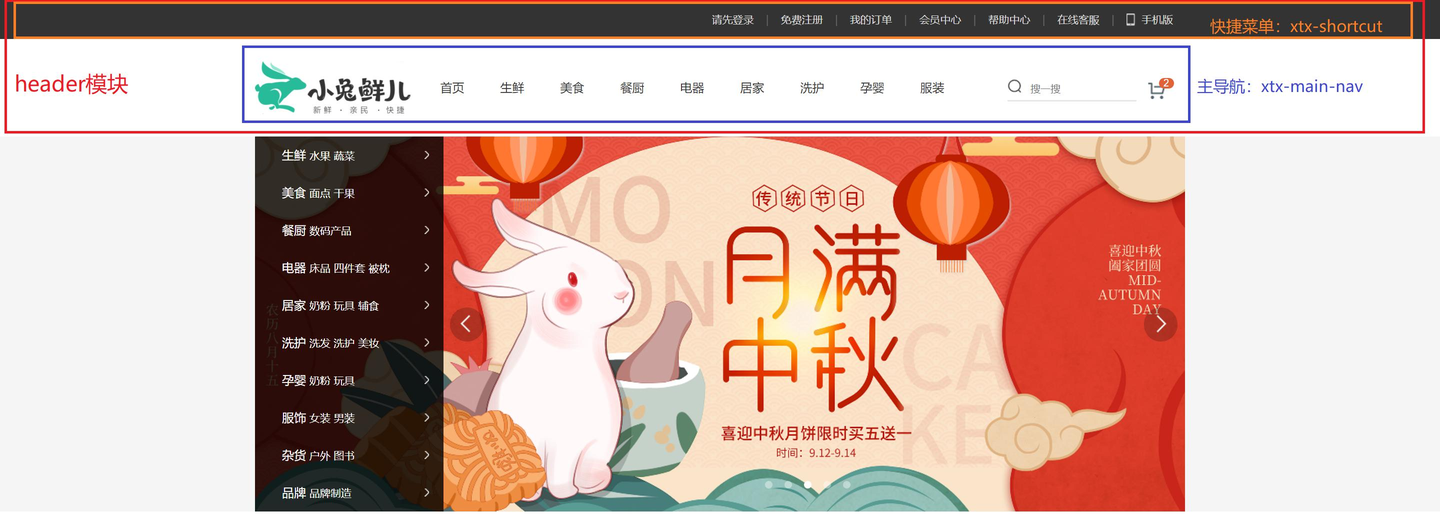

本日源码中，`.shortcut`和`.header.wrapper`是相邻的两个盒子，没有再用一个 `header` 外层包住它们。课件的 `xtx-shortcut`对应 `.shortcut`，`xtx-main-nav`对应 `.header.wrapper`。`.shortcut`内有版心，`.header`本身带 `.wrapper` 类。

实际开发按“外层尺寸 → 内部排布 → 文字和图标细节”的顺序进行，样式写入 `css/common.css`。


### 1.1 快捷导航：列表整体靠右，列表项排成一行

课件先框出通栏，再框出内部版心，最后让列表靠右。图中的 `.container` 对应本项目的 `.wrapper`。

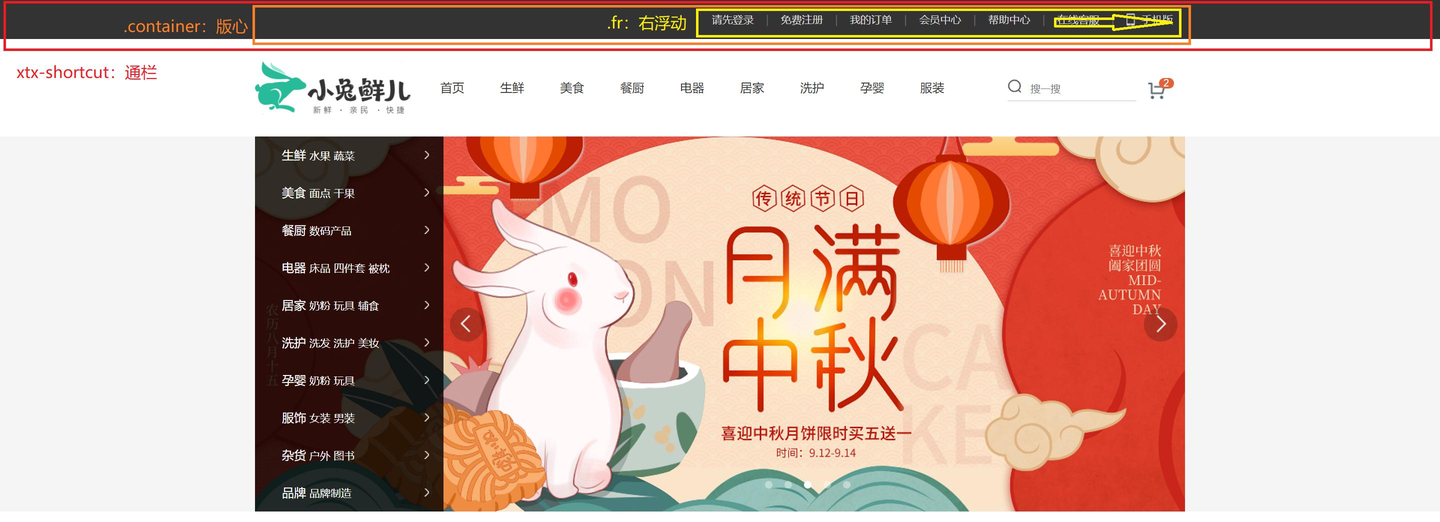

`index.html`快捷导航原文：

```html
    <!-- 快捷导航 -->
    <div class="shortcut">
        <div class="wrapper">
            <ul>
                <li><a href="#">请先登录</a></li>
                <li><a href="#">免费注册</a></li>
                <li><a href="#">我的订单</a></li>
                <li><a href="#">会员中心</a></li>
                <li><a href="#">帮助中心</a></li>
                <li><a href="#">在线客服</a></li>
                <li><a href="#"><span></span>手机版</a></li>
            </ul>
        </div>
    </div>
```

`css/common.css`对应规则：

```css
/* 快捷导航 */
.shortcut {
    height: 52px;
    background-color: #333;
}

.shortcut .wrapper {
    height: 52px;
}

/* 目的: 所有的文字内容居右侧对齐 */
.shortcut .wrapper ul {
    float: right;
}

/* 目的: 让所有的文字在一行显示 */
.shortcut .wrapper li {
    float: left;
    line-height: 52px;
}

.shortcut .wrapper a {
    padding: 0 16px;
    border-right: 1px solid #666;
    font-size: 14px;
    color: #dcdcdc;
}

.shortcut .wrapper a span {
    display: inline-block;
    margin-right: 8px;
    width: 11px;
    height: 16px;
    background-image: url(../images/sprites.png);
    background-position: -160px -70px;

    vertical-align: middle;
}

/* 清除a的边框线: 最后一个li里面的a */
.shortcut .wrapper li:last-child a {
    border: 0;
}
```

需要区分两级浮动：`ul`右浮动，把整个列表移到版心右侧；每个 `li`左浮动，让七个入口依次水平排列。只给 `ul`右浮动，并不会让内部的列表项自动排成一行。

快捷栏高度52px，列表项行高也为52px，单行文字因此垂直居中。链接左右各16px内边距，右边框作为分隔线，最后一个链接清除边框。

“手机版”前的空 `span`用11×16px盒子截取精灵图，坐标为 `-160px -70px`。它转为行内块后才能设置宽高；`vertical-align: middle`用于和文字对齐，右侧8px间距隔开图标与文字。

查看时应看到七个不同入口，最后一项有手机图标且没有右边框。本日已经把第09天反复出现的“请先登录”替换成对应文字；`href="#"`仍是占位链接。


### 1.2 主导航：先排logo、导航、搜索和购物车

课件把主导航拆成四个横向区域，各自左浮动。

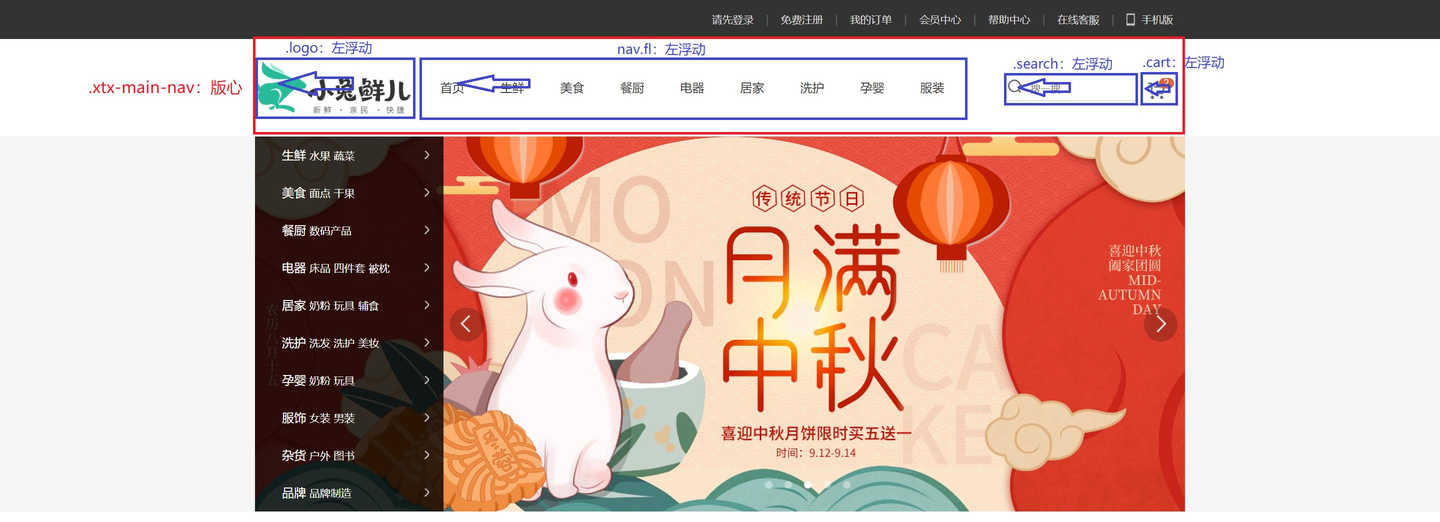

`index.html`主导航原文：

```html
    <!-- 头部 -->
    <div class="header wrapper">
        <div class="logo">
            <h1><a href="#">小兔鲜儿</a></h1>
        </div>
        <div class="nav">
            <ul>
                <li><a href="#">首页</a></li>
                <li><a href="#">生鲜</a></li>
                <li><a href="#">美食</a></li>
                <li><a href="#">餐厨</a></li>
                <li><a href="#">电器</a></li>
                <li><a href="#">居家</a></li>
                <li><a href="#">洗护</a></li>
                <li><a href="#">孕婴</a></li>
                <li><a href="#">服装</a></li>
            </ul>
        </div>
        <div class="search">
            <input type="text" placeholder="搜一搜">
            <!-- 定位 放大镜 -->
            <span></span>
        </div>
        <div class="car">
            <span>2</span>
        </div>
    </div>
```

四个区域都在 `.header.wrapper` 内。头部内容高70px，上下各30px外边距，总计占用130px的竖向空间。

`css/common.css`头部与logo规则：

```css
/* 头部 */
.header {
    margin: 30px auto;
    height: 70px;
}

.logo {
    float: left;
    width: 207px;
    height: 70px;
}

/* logo 搜索引擎优化做法 */
.logo h1 {
    width: 207px;
    height: 70px;
}

.logo h1 a {
    display: block;
    width: 207px;
    height: 70px;
    background-image: url(../images/logo.png);
    background-size: contain;
    /* 目的: 让h1里面的字看不见 */
    font-size: 0;
}
```

logo使用 `h1 > a`：保留“小兔鲜儿”文字作为标题内容，视觉上由背景图片呈现。链接转为块元素，整个207×70px区域都成为链接区域，`background-size: contain`按比例完整显示logo，`font-size: 0`隐藏文字。

补充：这是课堂的logo写法，不能据此保证搜索排名；链接也仍指向 `#`。背景缩放保持图片比例，所以图片未必正好填满盒子的每一像素。


### 1.3 导航栏目：间距、行高与悬停下划线

`css/common.css`导航规则：

```css
.nav {
    float: left;
    margin-left: 40px;
    height: 70px;
}

.nav li {
    float: left;
    margin-right: 48px;
    line-height: 70px;
}

.nav li a {
    padding-bottom: 7px;
}


.nav li a:hover {
    color: #27ba9b;
    border-bottom: 1px solid #27ba9b;
}
```

导航整体左浮动，左侧40px间距把它与logo隔开；各 `li`左浮动，右侧48px间距隔开栏目。70px行高与头部高度相等，用于单行文字垂直居中。

给 `a`设置7px下内边距，把悬停时的下边框放到文字下方。鼠标悬停后文字和边框都变成主题色 `#27ba9b`。

本日九个栏目是首页、生鲜、美食、餐厨、电器、居家、洗护、孕婴、服装。查看时应排在一行，悬停某个链接时才显示绿色下线。

补充：源码没有去掉最后一个 `li`的右外边距，计算头部剩余宽度时要把它计入。不要只看文字宽度就判断四个区域一定能放下。


### 1.4 搜索框：输入文字给图标留位置

`css/common.css`搜索规则：

```css
.search {
    position: relative;
    float: left;
    margin-top: 24px;
    margin-left: 34px;
    width: 172px;
    height: 30px;
    border-bottom: 2px solid #e7e7e7;
}

.search input {
    padding-left: 30px;
    width: 172px;
    height: 28px;
}

.search input::placeholder {
    font-size: 14px;
    color: #ccc;
}

.search span {
    position: absolute;
    left: 2px;
    top: 0;
    /* display: inline-block; */
    width: 18px;
    height: 18px;
    background-image: url(../images/sprites.png);
    background-position: -79px -69px;
}
```

搜索区域宽172px、高30px，下边框2px；输入框高28px，在全局内减模式下与外层边框配合。区域上边距24px让它落在主导航中部。

放大镜采用“父相子绝”：`.search`相对定位，空 `span`绝对定位到左侧2px、顶部0。18×18px图标从精灵图的 `-79px -69px`处截取。

输入框左侧30px内边距让输入文字与“搜一搜”提示都避开图标。`::placeholder`只设置提示文字的14px字号和浅灰色，不改变实际输入内容的字号。

源码中 `display: inline-block`被注释，图标实际依靠绝对定位获得可设置宽高的盒子。查看时放大镜应在下划线上方，文字输入后不应压到图标上。

补充：当前没有表单提交逻辑，也没有搜索按钮；空 `span`只显示装饰图标。


### 1.5 购物车：精灵图与右上角数量

`css/common.css`购物车规则：

```css
.car {
    position: relative;
    float: left;
    margin-top: 28px;
    margin-left: 15px;
    width: 23px;
    height: 23px;
    background-image: url(../images/sprites.png);
    background-position: -119px -69px;
}

.car span {
    /* 绝对定位, 盒子具备行内块特点 */
    position: absolute;
    right: -13px;
    top: -6px;
    width: 20px;
    height: 15px;
    background-color: #e26237;
    border-radius: 8px;

    font-size: 13px;
    color: #fff;
    text-align: center;
    line-height: 15px;
}
```

购物车本体是23×23px精灵图盒子，背景坐标 `-119px -69px`。数量 `span`以购物车为定位参照，`right: -13px`和 `top: -6px`使角标伸到右上角外侧。

角标20×15px，橙色背景，8px圆角；15px行高与盒子高度一致，配合居中对齐显示数字。

查看时应显示数字“2”，角标部分超出购物车轮廓。这是HTML里的固定文字，当前没有购物车数量计算。

本项目共用精灵图如下。后续分类箭头、轮播箭头和“查看全部”箭头也使用它，但每个图标的盒子尺寸与坐标不同。

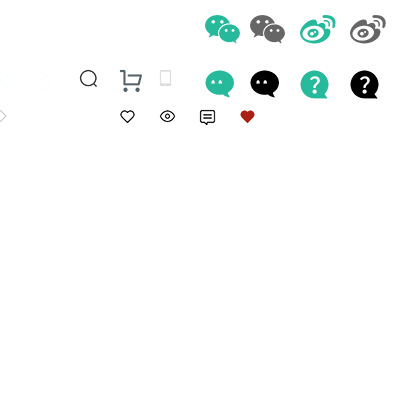


## 2. Footer部分开发

原课把完整页脚拆成联系方式 `xtx-contact`、宣传服务 `xtx-service`、版权信息 `xtx-copyright`。

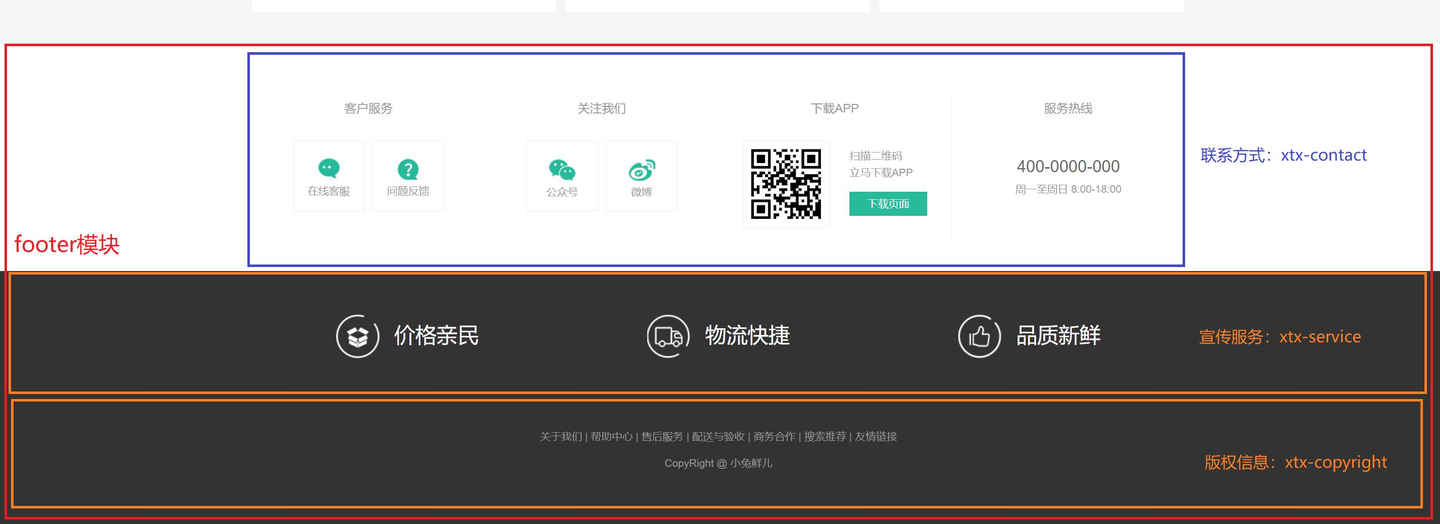

本日配套源码的 `.footer`只包含深色区域：`.top`对应宣传服务，`.bottom`对应版权信息。图中白色的客服、关注、下载APP和热线区域没有对应HTML或CSS。

补充：读图时保留这一层整体划分；下面只写本日源码实际提供的深色区域，不凭效果图补出联系方式区域的尺寸和实现。


### 2.1 宣传服务：三个横向项目

课件先框出通栏和版心，再把三个服务项目排成一行。

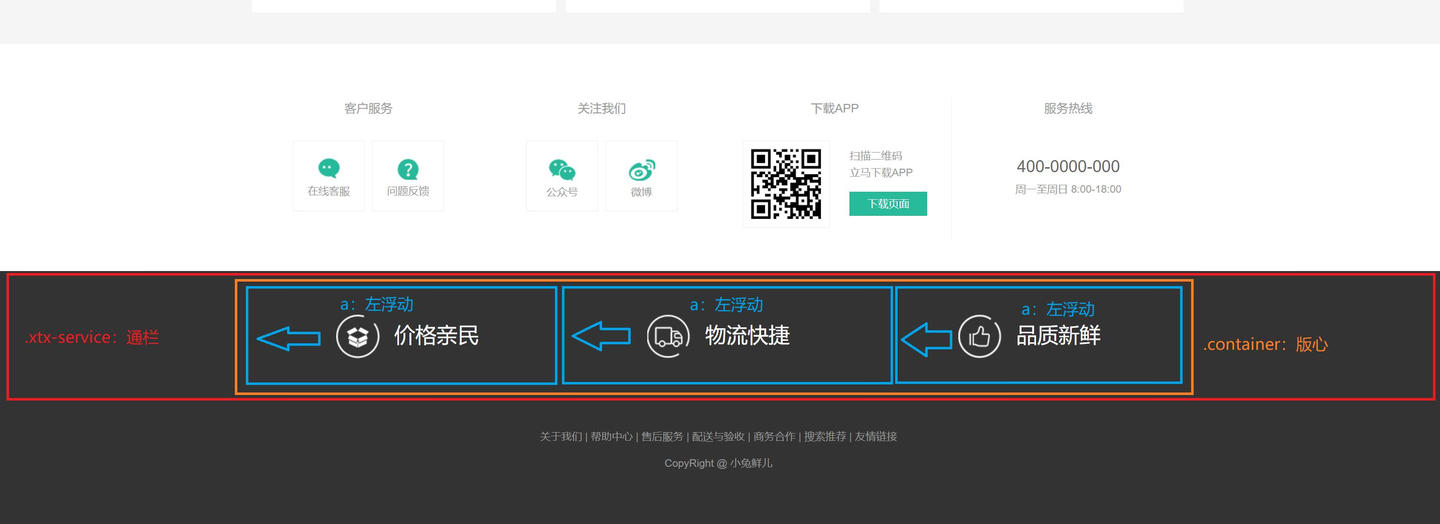

`index.html`页脚原文如下，包含服务、版权和页面结束标签：

```html
    <!-- 版权区域 -->
    <div class="footer">
        <div class="wrapper">
            <div class="top">
                <ul>
                    <li>
                        <!-- 通过伪元素添加标签实现精灵图 -->
                        <span>价格亲民</span>
                    </li>
                    <li>
                        <span>物流快捷</span>
                    </li>
                    <li>
                        <span>品质新鲜</span>
                    </li>
                </ul>
            </div>
            <div class="bottom">
                <p>
                    <a href="#">关于我们</a> |
                    <a href="#">帮助中心</a> |
                    <a href="#">售后服务</a> |
                    <a href="#">配送与验收</a> |
                    <a href="#">商务合作</a> |
                    <a href="#">搜索推荐</a> |
                    <a href="#">友情链接</a>
                </p>
                <p>CopyRight @ 小兔鲜儿</p>
            </div>
        </div>
    </div>
</body>

</html>
```

补充：课件图用三个 `a`说明左浮动，源码实际用三个 `li`包含 `span`文字，没有把服务项做成可点击链接。

`css/common.css`页脚上部规则：

```css
/* 版权footer */
.footer {
    height: 342px;
    background-color: #333;
}

.footer .wrapper {
    width: 1393px;
}

.footer .top {
    padding-top: 59px;
    padding-left: 135px;
    height: 175px;
    border-bottom: 3px solid #434343;
}

.footer .top li {
    position: relative;
    float: left;
    margin-right: 300px;
    width: 195px;
    height: 58px;

    line-height: 58px;
}

.footer .top li:last-child {
    margin-right: 0;
}

/* 伪元素添加的标签  行内 */
/* 如果行内块和行内文字无法通过vertical-align或行高对齐, 定位 */
.footer .top li::before {
    position: absolute;
    left: 0;
    top: 0;
    /* display: inline-block; */
    content: '';
    width: 58px;
    height: 58px;
    background-image: url(../images/sprites.png);
    vertical-align: middle;
}

.footer .top li span {
    margin-left: 77px;
    font-size: 28px;
    color: #fff;
}

/* 第二个li里面的berfore添加背景图位置属性 */
.footer .top li:nth-child(2)::before {
    background-position: -130px 0;
}
.footer .top li:nth-child(3)::before {
    background-position: -64px 0;
}
```

页脚通栏高342px，背景 `#333`。本区域将 `.wrapper`宽度覆盖成1393px，上部高175px，顶部内边距59px，左侧内边距135px，下方3px分隔线。

每项宽195px、高58px、左浮动，前两项各有300px右外边距，最后一项清零。三个项目的总宽度为：

```text
195 × 3 + 300 × 2 = 1185px
1393 - 135 = 1258px（版心扣除左内边距后的可用宽度）
```

1185px小于1258px，所以这组尺寸可以排在一行。版心和页脚尺寸不能直接套用主体的1240px。


### 2.2 图标与文字：伪元素定位，按项目切换坐标

每个 `li`相对定位，`::before`生成58×58px图标盒子，绝对定位到项目左上角。`content: ''`使伪元素生成，背景图显示服务图标。

文字用77px左外边距避开图标，字号28px，颜色白色；58px行高与项目高度相等。原代码注释也提醒：图标和文字通过行高或 `vertical-align`难以对齐时，可用定位安排图标。

本日三个图标坐标分别是：

| 项目 | 精灵图位置 | 与第09天相比 |
| --- | --- | --- |
| 价格亲民 | 默认 `0 0` | 沿用第一个图标 |
| 物流快捷 | `-130px 0` | 第二项从 `-64px 0`调整为此坐标 |
| 品质新鲜 | `-64px 0` | 新增第三项独立规则 |

补充：`display: inline-block`被注释；伪元素实际采用绝对定位。保留的 `vertical-align: middle`不是这里图标定位对齐的主要依据。

查看时三个服务应显示不同图标，分别对应箱子、货车与点赞，文字也已从重复的“价格亲民”换成三种服务。


### 2.3 版权：两行内容整体居中

课件将版权区域划分为两个默认独占一行的 `p`标签。

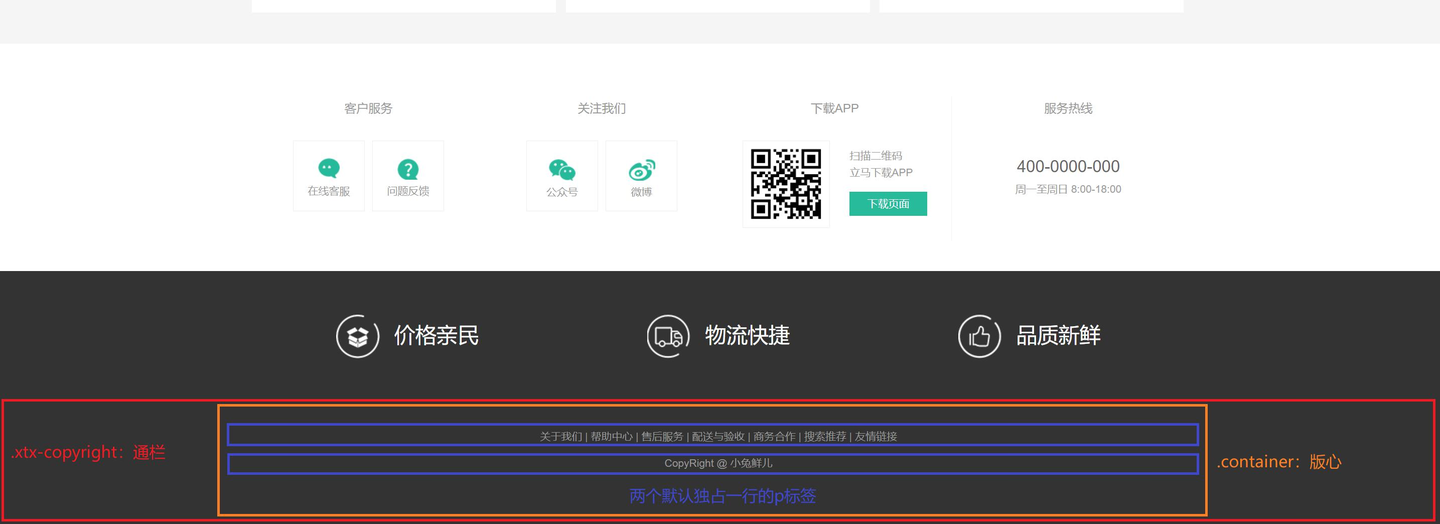

`css/common.css`页脚下部规则：

```css
.footer .bottom {
    padding-top: 40px;
    font-size: 14px;
    color: #999;
    text-align: center;
}

.footer .bottom a {
    font-size: 14px;
    color: #999;
}

.footer .bottom p {
    margin-bottom: 20px;
}
```

上方40px内边距把版权内容与分隔线隔开；文字14px、灰色，整体居中。链接也设置同样颜色，避免沿用基础样式中的深色。段落下方20px外边距隔开两行。

第一行是七个入口，中间的 `|`是HTML中的文本；第二行保留原文 `CopyRight @ 小兔鲜儿`。当前链接仍使用 `#`。

查看时服务下面有水平分隔线，再显示居中的两行版权内容。页脚在正常文档流里跟随主体排列，没有固定到浏览器底部。


## 3. 网站入口xtx-entry部分开发

网站入口包括一张横幅、覆盖在左侧的分类导航、上一张与下一张箭头，以及底部圆点。课件强调先建立通栏，再在版心里放内容。

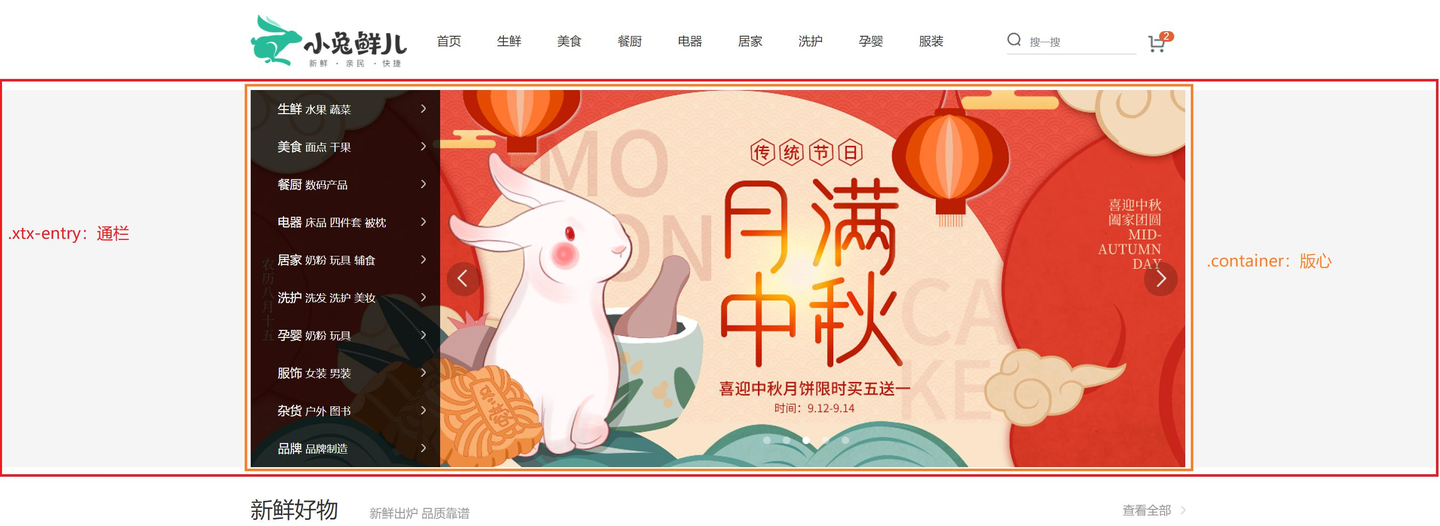

本项目用 `.banner`作为通栏，内部 `.wrapper`作为定位参照。原课图上的 `.banner`是图片层名称，与本项目外层同名，但层级含义不同，应按下面源码理解。

主体HTML插在主导航之后、页脚之前；首页主体CSS写入 `css/index.css`。


### 3.1 横幅图片铺满版心，版心作为定位参照

课件中的图片层占满版心一行，分类菜单是在上面覆盖显示，而不是先扣掉分类宽度再放图。

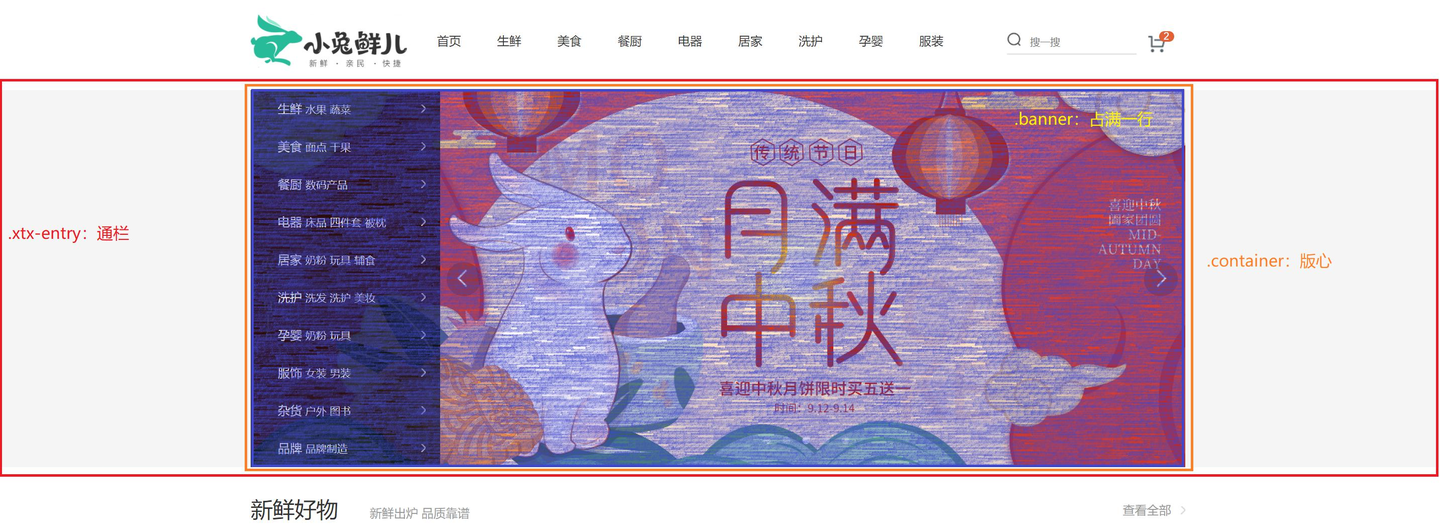

`index.html`入口开头原文，以下几节的HTML片段依次接在一起：

```html
    <!-- banner -->
    <div class="banner">
        <div class="wrapper">
            <!-- 有多少个图,就有都少个li -->
            <ul>
                <li>
                    <a href="#"><img src="./uploads/banner_1.png" alt=""></a>
                </li>
            </ul>
```

`css/index.css`入口外层规则：

```css
/* 放index页面的样式表 */
/* banner */
.banner {
    height: 500px;
    background-color: #f5f5f5;
}

.banner .wrapper {
    position: relative;
    height: 500px;
    background-color: pink;
}
```

通栏高度500px、浅灰背景；内层版心宽度继承1240px，高度也为500px，并设置 `position: relative`。分类、箭头、圆点之后都以它为绝对定位参照。

`uploads/banner_1.png`原图就是1240×500px，因此这份源码没有另外给横幅图片设置宽高，按图片自身尺寸即可填满版心。`ul > li > a > img`为轮播图片准备列表结构，但当前只放了一项。

补充：内层 `background-color: pink`是课堂用于观察盒子范围的颜色，本日源码仍保留；图片覆盖完整时通常看不到。源码没有横幅裁切或多图切换规则，不能直接追加多张 `li`就认为轮播已经完成。

查看时横幅应完整出现在主导航下方，两侧的浅灰通栏延伸到窗口边缘。


### 3.2 分类导航覆盖在图片左上角

课件图中的 `.category`定位到版心左上角，对应源码的 `.aside`。

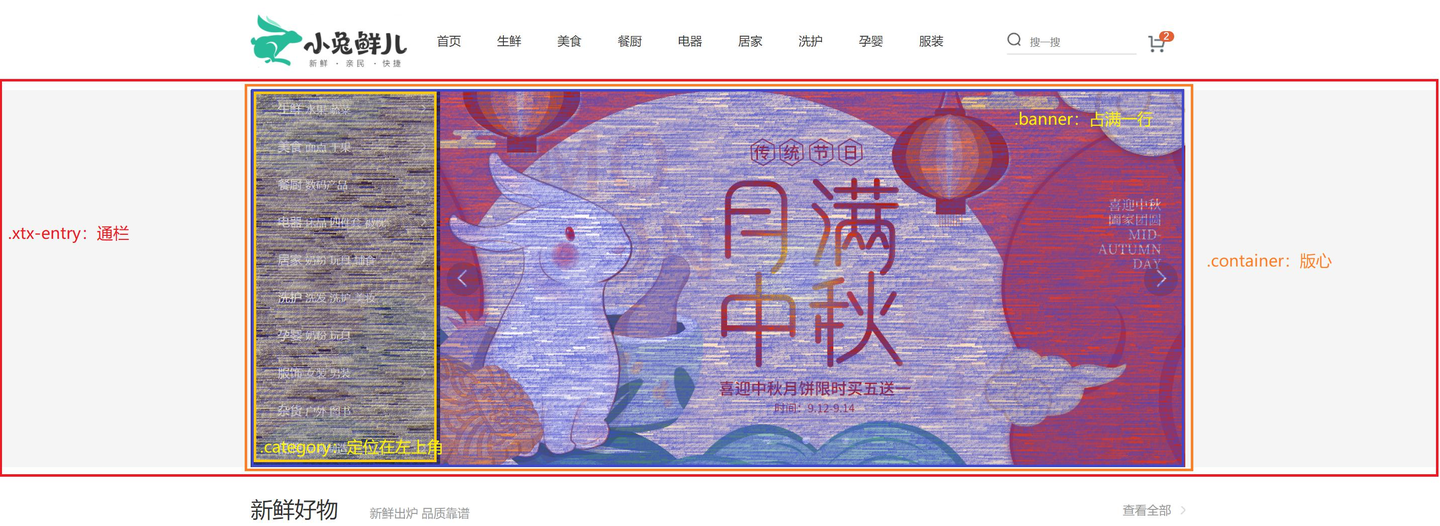

`index.html`紧接横幅列表后的分类结构：

```html
            <!-- 侧导航 -->
            <div class="aside">
                <ul>
                    <li><a href="#">生鲜<span>水果 蔬菜</span></a></li>
                    <li><a href="#">生鲜<span>水果 蔬菜</span></a></li>
                    <li><a href="#">生鲜<span>水果 蔬菜</span></a></li>
                    <li><a href="#">生鲜<span>水果 蔬菜</span></a></li>
                    <li><a href="#">生鲜<span>水果 蔬菜</span></a></li>
                    <li><a href="#">生鲜<span>水果 蔬菜</span></a></li>
                    <li><a href="#">生鲜<span>水果 蔬菜</span></a></li>
                    <li><a href="#">生鲜<span>水果 蔬菜</span></a></li>
                    <li><a href="#">生鲜<span>水果 蔬菜</span></a></li>
                    <li><a href="#">生鲜<span>水果 蔬菜</span></a></li>
                </ul>
            </div>
```

`css/index.css`对应规则：

```css
/* 侧导航 */
.banner .aside {
    position: absolute;
    left: 0;
    top: 0;
    width: 250px;
    height: 500px;
    background-color: rgba(0,0,0,.8);
}

.banner .aside li {
    height: 50px;
    line-height: 50px;
}

.banner .aside a {
    position: relative;
    /* 宽度和父级一样 */
    padding-left: 36px;
    padding-right: 19px;
    display: block;
    height: 50px;

    color: #fff;
}

.banner .aside a span {
    margin-left: 15px;
    font-size: 14px;
}

.banner .aside a:hover {
    background-color: #27ba9b;
}

/* a的里面最后的位置添加箭头 */
.banner .aside a::after {
    position: absolute;
    right: 19px;
    top: 19px;
    content: '';
    width: 6px;
    height: 11px;
    background-image: url(../images/sprites.png);
    background-position: -80px -110px;
}
```

`.aside`宽250px、高500px，绝对定位到版心左上角。绝对定位脱离普通文档流，不会把横幅挤到右边；`rgba(0,0,0,.8)`只让黑色背景有透明度，白色文字保持可读。

10项菜单各50px高，正好占满500px。每项链接转为块级，扩大到整行可悬停；左右内边距分别36px和19px。主分类沿用16px字号，`span`里的子分类14px，左侧间距15px。

鼠标悬停时链接背景变为绿色。每项右侧箭头由 `a::after`添加，`a`相对定位，伪元素绝对定位到右侧19px、顶部19px；图标6×11px，精灵坐标 `-80px -110px`。

由于全局采用内减模式，链接的左右内边距不会把这一行撑出父级宽度。箭头定位在行尾，也不会参与分类文字的横向排列。

补充：课件图展示十种不同类别，源码当前十项都写成 `生鲜<span>水果 蔬菜</span>`。这里保留重复内容以说明布局，不把效果图里的分类文字当成已经实现。

查看时左侧是半透明分类栏，横幅从它后面延伸；悬停一行时整行变绿，右端箭头保持在相同位置。


### 3.3 左右箭头：圆形盒子与精灵图位置一起调试

`index.html`分类之后的箭头结构：

```html
            <!-- 箭头 -->
            <!-- prev: 上一个 -->
            <a href="#" class="prev"></a>
            <!-- next : 下一个 -->
            <a href="#" class="next"></a>
```

`css/index.css`箭头规则，保留课堂调试说明：

```css
/* 箭头 */
.next,
.prev {
    position: absolute;
    top: 228px;
    width: 45px;
    height: 45px;
    background-color: rgba(0,0,0,.2);
    background-image: url(../images/sprites.png);
    border-radius: 50%;
}

/* 背景图位置负责2件事: 改变箭头在盒子里面的位置; 改变精灵图的位置 */
/* 导致在精灵图中测量的尺寸不准确 */
/* 解决方案有2种: 
    1. 书写背景图位置属性, 借助谷歌的调试工具调试具体的位置数值
    2. 书写标签的时候, a负责盒子,里面再添加一个span负责箭头
*/
.prev {
    left: 260px;
    background-position: 14px -60px;
}

.next {
    right: 10px;
    background-position: -23px -60px;
}
```

两个箭头共用45×45px圆形盒子，背景为半透明黑色，`border-radius: 50%`使正方形呈圆形。它们绝对定位在版心中，顶部228px。

上一张按钮在 `left: 260px`，即避开250px分类栏后再向右10px；下一张按钮在 `right: 10px`。相对于500px高的区域，按钮顶部228px使它接近竖直中心。

这里的 `background-position`同时决定“截取精灵图哪一块”和“箭头在45px盒子内落在哪里”。因此不能只抄精灵图测量出的负坐标，还需要把箭头摆到圆形按钮中央。

原代码说明了两种处理方式：

1. 直接在当前背景位置规则上调试，借助浏览器开发者工具调整数值；这份源码采用了这种方式。
2. `a`只负责圆形盒子，内部增加 `span`负责箭头图标，使按钮位置与精灵图位置分开；这是课堂注释中的另一种做法，本日HTML没有采用它。

查看时箭头应在分类栏右侧与横幅最右侧，图标位于圆形按钮中部。点击目前只触发占位链接，不切换图片。


### 3.4 底部圆点：静态当前状态

`index.html`入口末尾原文，最后两个 `</div>`依次结束版心和通栏：

```html
            <!-- 圆点: 当前状态: current / active -->
            <!-- js 找到用户点击的li 添加类名 li变成白色的 -->
            <ol>
                <li></li>
                <li></li>
                <li class="current"></li>
                <li></li>
                <li></li>
            </ol>
        </div>
    </div>
```

`css/index.css`圆点规则：

```css
/* 圆点 */
.banner ol {
    position: absolute;
    left: 680px;
    bottom: 30px;

    height: 10px;
}

.banner ol li {
    float: left;
    margin-right: 24px;
    width: 10px;
    height: 10px;
    background-color: rgba(255, 255, 255, 0.4);
    border-radius: 50%;
    cursor: pointer;
}

.banner ol .current {
    background-color: #fff;
}
```

`ol`绝对定位到版心左侧680px、底部30px。五个 `li`左浮动，每个10×10px，右侧间距24px；半透明白色表示普通状态，`.current`使用不透明白色。

第三个圆点在HTML里静态添加了 `current`类。`cursor: pointer`只是改变鼠标形状，不能实现点击逻辑。

补充：HTML注释提到“JS找到用户点击的li添加类名”，但本项目没有脚本；图片只有一张，而圆点有五个，这是一份展示结构与状态样式的课堂实现。不要把第三个白点解释成当前已经展示第三张图片。

查看时应出现五个圆点，第三个更亮；当前点击不会切换亮点或横幅。入口的练习重点是用定位实现各层重叠关系。


## 4. 新鲜好物面板xtx-new-goods部分开发

原课先框出整个版心面板，再拆成上方标题栏和下方商品列表。标题栏左侧放主标题与说明，右侧放“查看全部”；内容区是四个横向卡片。

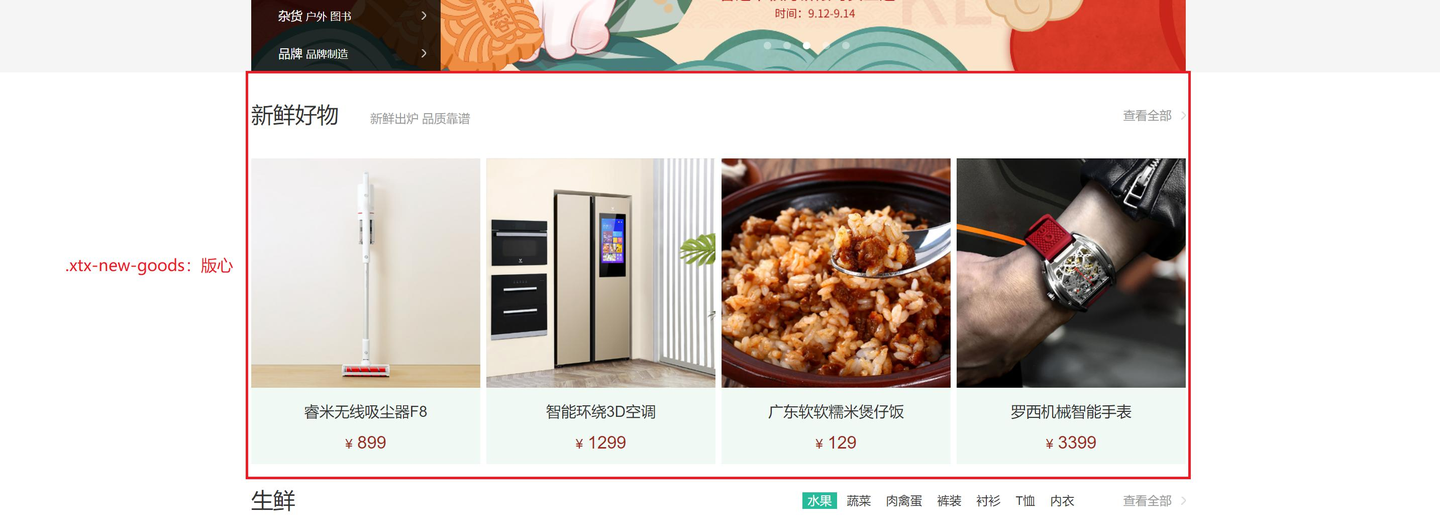

本项目用 `.goods.wrapper`实现面板，`.hd`代表头部，`.bd`代表内容区。标题与商品的样式都写入 `css/index.css`。


### 4.1 先搭完整结构：标题与四张卡片

`index.html`新鲜好物区域原文：

```html
    <!-- 新鲜好物 -->
    <div class="goods wrapper">
        <!-- hd header 头部 -->
        <div class="hd">
            <h2>新鲜好物<span>新鲜出炉 品质靠谱</span></h2>
            <a href="#">查看全部</a>
        </div>
        <!-- body 身体, 内容 -->
        <div class="bd clearfix">
            <ul>
                <li>
                    <a href="#">
                        <img src="./uploads/new_goods_1.jpg" alt="">
                        <h3>睿米无线吸尘器F8</h3>
                        <div>￥<span>899</span></div>
                        <b>新品</b>
                    </a>
                </li>
                <li>
                    <a href="#">
                        <img src="./uploads/new_goods_1.jpg" alt="">
                        <h3>睿米无线吸尘器F8</h3>
                        <div>￥<span>899</span></div>
                        <b>新品</b>
                    </a>
                </li>
                <li>
                    <a href="#">
                        <img src="./uploads/new_goods_1.jpg" alt="">
                        <h3>睿米无线吸尘器F8</h3>
                        <div>￥<span>899</span></div>
                    </a>
                </li>
                <li>
                    <a href="#">
                        <img src="./uploads/new_goods_1.jpg" alt="">
                        <h3>睿米无线吸尘器F8</h3>
                        <div>￥<span>899</span></div>
                    </a>
                </li>

            </ul>
        </div>
    </div>
```

`h2`里的 `span`是标题旁的说明文字。商品列表使用 `ul > li`，每项里面的 `a`包住图片、名称、价格和可能出现的新品标签。

价格拆为货币符号与 `span`里的数字，便于设置两种字号。只有前两个商品包含 `<b>新品</b>`，后两个没有这个标签。

内容区加 `.clearfix`，使父盒子包含下面浮动卡片的高度，后续生鲜面板才能排在整行商品之后。

补充：课件效果图展示四种商品，配套HTML四项都使用 `new_goods_1.jpg`、名称“睿米无线吸尘器F8”和价格899。文件夹虽然包含其他商品图片，但原代码没有引用它们。当前查看时会出现四张相同商品卡片。


### 4.2 标题栏：主标题靠左，查看全部靠右

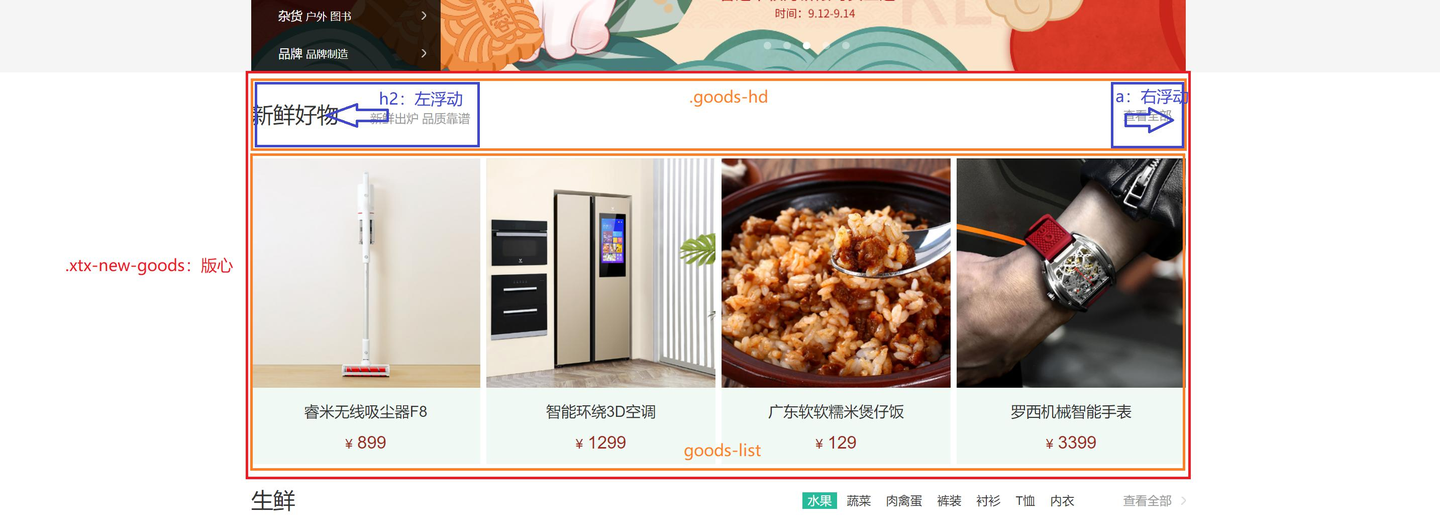

`css/index.css`标题栏规则：

```css
/* 新鲜好物 */

.goods .hd {
    height: 114px;
    line-height: 114px;
}

.goods .hd h2 {
    float: left;
    font-size: 29px;
    font-weight: 400;

    height: 114px;
}

.goods .hd h2 span {
    margin-left: 34px;
    font-size: 16px;
    color: #999;
}

.goods .hd a,
.shengxian .hd .more {
    float: right;
    color: #999;
}

.goods .hd a::after,
.shengxian .hd .more::after {
    content: '';
    display: inline-block;
    margin-left: 13px;
    width: 7px;
    height: 13px;
    background-image: url(../images/sprites.png);
    background-position: 0 -110px;
    vertical-align: middle;
}
```

标题栏高114px，行高也是114px。主标题左浮动，29px字号，取消默认粗体；说明文字16px、灰色，与主标题间隔34px。右侧链接右浮动，灰色。

“查看全部”后的箭头由 `::after`生成，转为行内块后设置7×13px尺寸，与文字之间留13px间距；精灵图坐标 `0 -110px`，用 `vertical-align: middle`与链接文字对齐。

这两组右侧链接规则使用并集选择器，同时覆盖 `.goods .hd a`和 `.shengxian .hd .more`。因此生鲜面板的“查看全部”会复用颜色、右浮动与箭头。

查看时标题、说明和右侧入口应在同一标题栏中。`h2`本身高114px；本区域通过固定高度支撑浮动内容，没有另外添加 `.clearfix`。


### 4.3 商品列表：四列刚好占满1240px

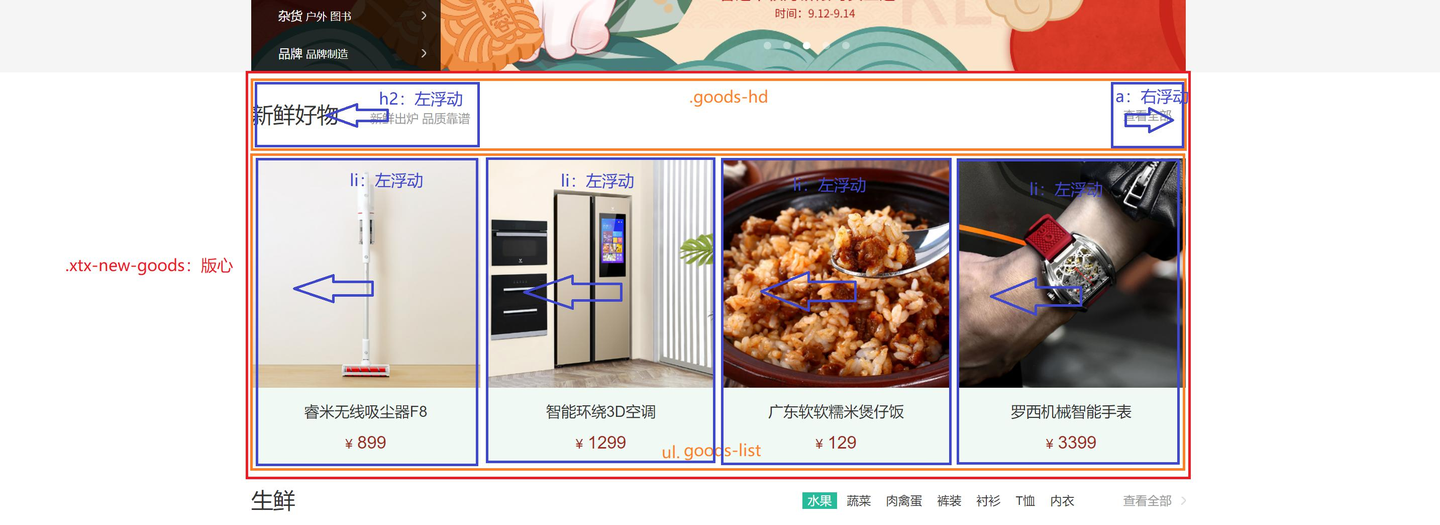

`css/index.css`卡片规则：

```css
.goods .bd li {
    position: relative;
    float: left;
    margin-right: 8px;
    width: 304px;
    height: 405px;
    background-color: #f0f9f4;
    text-align: center;
}

.goods .bd li:last-child {
    margin-right: 0;
}

.goods .bd li img {
    width: 304px;
}

.goods .bd li h3 {
    margin-top: 20px;
    margin-bottom: 10px;
    font-size: 20px;
    font-weight: 400;
}

.goods .bd li div {
    color: #9a2e1f;
    font-size: 17px;
}

.goods .bd li div span {
    font-size: 23px;
}
```

每张卡片宽304px、高405px，左浮动，右间距8px；最后一张清除右间距。宽度关系是：

```text
304 × 4 + 8 × 3 = 1240px
```

如果最后一张仍保留8px间距，总宽度会变成1248px，可能造成换行。`li:last-child`用于让一行正好放入版心。

图片只指定304px宽度。`new_goods_1.jpg`原图是611×611px的正方形，所以等比缩放后显示为304×304px。

卡片整体文字居中。名称上方20px、下方10px间距，字号20px且不加粗；价格颜色 `#9a2e1f`，符号17px，数字23px。

查看时四张卡片同宽、同高，并排一行，下方是浅绿色文字背景。商品名称和价格应居中，后面的生鲜标题应在商品区之后。

补充：当前尺寸是针对课堂素材设定的固定卡片，换成长名称或不同比例图片时要重新核对是否溢出；本日没有加入裁切和多行省略规则。


### 4.4 新品标签：定位在卡片左上方

`css/index.css`新品标签规则：

```css
.goods .bd li b {
    position: absolute;
    left: 17px;
    top:18px;
    width: 28px;
    height: 51px;
    border: 1px solid #27ba9b;
    border-radius: 2px;
    font-size: 18px;
    color: #27ba9b;
    font-weight: 400;
    line-height: 24px;
}
```

每张商品 `li`已相对定位，所以内部 `b`以它为参照，绝对定位到左侧17px、顶部18px，覆盖在商品图片上。

标签28px宽、51px高，绿色边框与文字，2px圆角；18px字号，取消 `b`默认粗体。内减模式下内容宽度只有26px，两个汉字不能放在同一行，因此“新品”自然分成上下两行，24px行高控制行距。

这里没有使用 `writing-mode`或 `<br>`，纵向效果来自窄盒子里的文字换行。只要HTML有 `b`就会出现标签；源码前两张有，后两张没有。

查看时前两张卡片左上角应有绿色“新品”标签，后两张不显示。


## 5. 生鲜商品面板xtx-fresh-goods部分开发

原课继续沿用“标题栏 + 内容区”的结构。标题栏新增分类入口；内容区左边是大封面，右边是两行商品卡片。

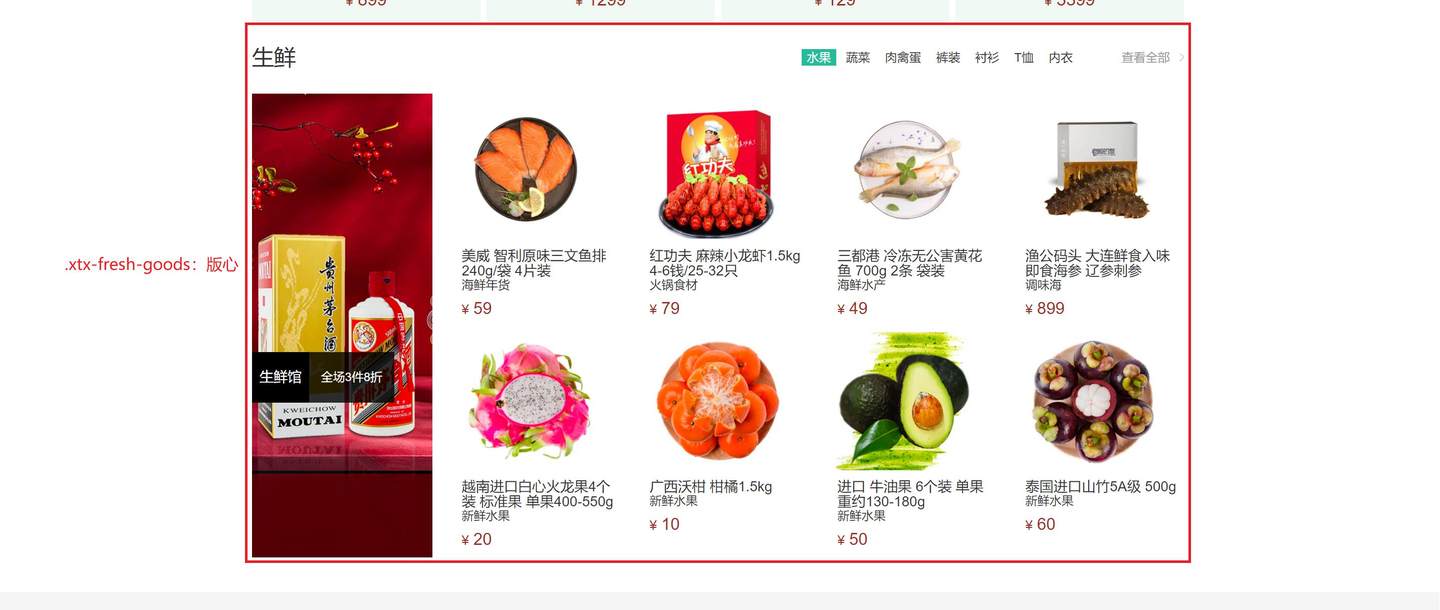

对应源码为 `.shengxian.wrapper`。下面先写本日已有的标题、左右布局，再保留课件对商品列表的拆分，区分设计目标与实际源码。


### 5.1 标题栏结构：先写查看全部，再写分类列表

课件用 `h2`左浮动，把分类 `ul.tab`和“查看全部”链接放在右侧。

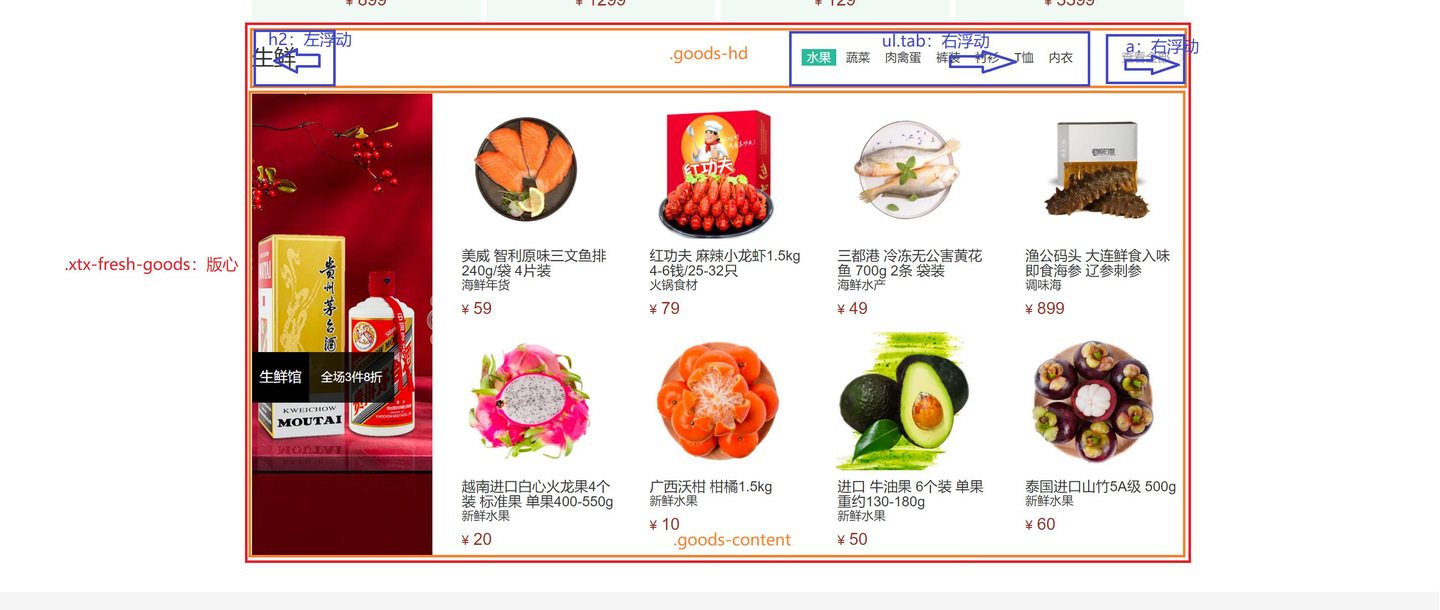

`index.html`生鲜区域原文：

```html
    <!-- 生鲜 -->
    <div class="shengxian wrapper">
        <div class="hd">
            <h2>生鲜</h2>
            <a href="#" class="more">查看全部</a>
            <ul>
                <li><a href="#">水果</a></li>
                <li><a href="#">水果</a></li>
                <li><a href="#">水果</a></li>
                <li><a href="#">水果</a></li>
                <li><a href="#">水果</a></li>
                <li><a href="#">水果</a></li>
                <li><a href="#">水果</a></li>
            </ul>
        </div>
        <div class="bd clearfix">
            <div class="left">
                <a href="#"><img src="./uploads/fresh_goods_cover.png" alt=""></a>
            </div>
            <div class="right"></div>
        </div>
    </div>
```

标题栏里先写 `h2`，然后写右浮动的“查看全部”，再写右浮动的分类列表。多个元素右浮动时，先写的元素先占右边位置，因此这个顺序使“查看全部”在最右侧，分类位于它左边。

`css/index.css`标题与分类规则：

```css
/* 生鲜 */
.shengxian .hd {
    height: 96px;
    line-height: 96px;
}

.shengxian .hd h2 {
    float: left;
    font-size: 29px;
    font-weight: 400;
}

.shengxian .hd .more {
    float: right;
}

.shengxian .hd ul {
    float: right;
    margin-right: 65px;
}

.shengxian .hd ul li {
    float: left;
}

.shengxian .hd li a {
    padding: 2px 7px;
    margin-left: 6px;
}

.shengxian .hd li a:hover {
    background-color: #27ba9b;
    color: #fff;
}
```

标题栏高96px、行高96px，主标题29px不加粗。分类 `ul`右浮动，与最右侧入口隔开65px；各分类 `li`左浮动，让分类内部仍按源码顺序从左到右排。

分类链接左右各7px、上下各2px内边距，左外边距6px。悬停时背景变绿色、文字变白。

“查看全部”的灰色、右侧箭头已在新鲜好物部分的并集选择器里定义。此处再次写 `.more { float: right; }`是原文件保留的重复规则，没有其他新效果。

补充：课件图中有不同分类，且“水果”显示绿色选中状态。当前源码七项都写“水果”，只有 `:hover`样式，没有静态选中类，也没有分类筛选逻辑。查看时悬停哪一项，哪一项才变绿。


### 5.2 内容区：左侧240px封面，右侧1000px区域

课件把内容区拆成左侧 `.goods-pic`和右侧商品列表。源码中对应 `.left`和 `.right`两个盒子，均左浮动。

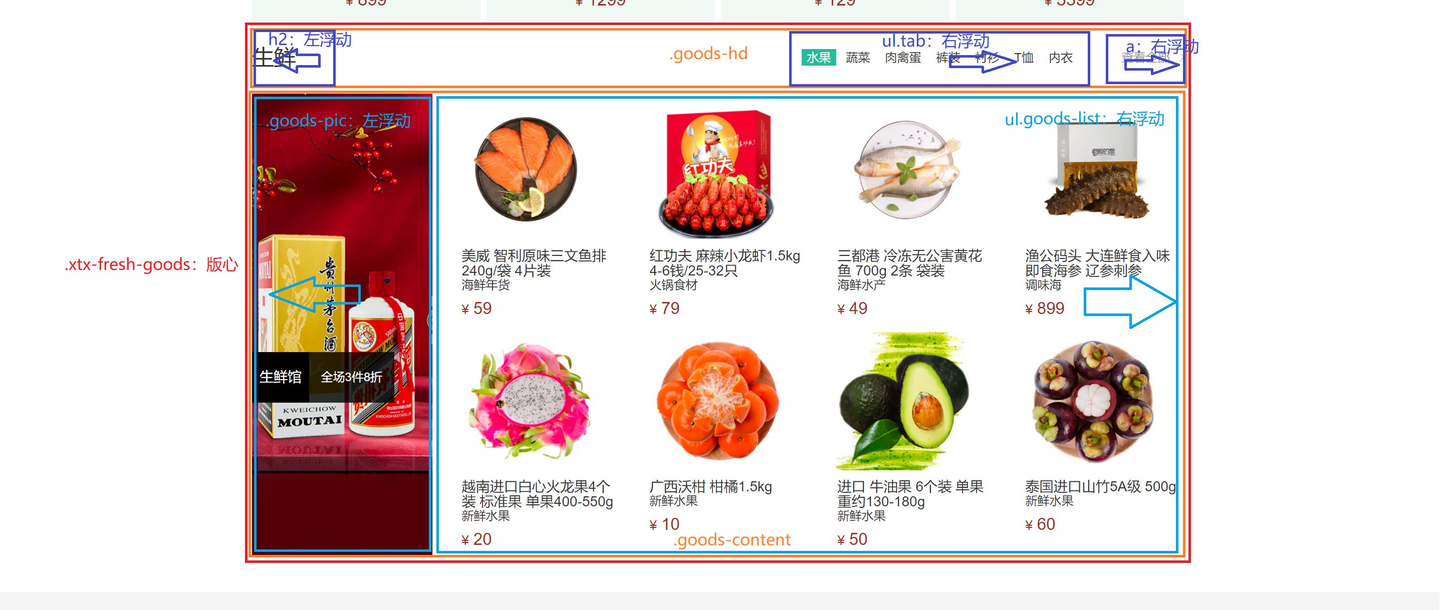

`css/index.css`本日最后一组规则：

```css
.shengxian .bd .left {
    float: left;
    width: 240px;
    height: 610px;
    background-color: pink;
}

.shengxian .bd .right {
    float: left;
    width: 1000px;
    height: 610px;
    background-color: skyblue;
}
```

两列的宽度正好组成版心：

```text
240 + 1000 = 1240px
```

两列高610px。左列放 `uploads/fresh_goods_cover.png`，原图为240×610px，所以当前HTML不额外设置图片尺寸也能与左列一致。封面的图片和文案已经在素材中，不是HTML再叠出两行文字。

右列在HTML中是空 `div`。粉色、天蓝色背景用于观察两列范围，本日源码仍保留；左侧封面会覆盖粉色背景，右侧没有内容，所以会显示整块天蓝色。

内容父盒子 `.bd`加 `.clearfix`，即使左右两列都浮动，也能支撑610px高度，页脚应从这个区域之后开始。

查看时应看到左边的生鲜封面和右边的天蓝色空区域，两列处于同一行。若右列被挤到下一行，先检查总宽度、额外间距与是否沿用内减模式。


### 5.3 原课商品列表拆分与本日完成边界

原课最后一张布局图把右侧区域进一步拆成两行、每行四个商品。每个商品由图片、商品信息、简短分类说明和价格构成；商品项继续左浮动，在固定内容宽度内排成多行。

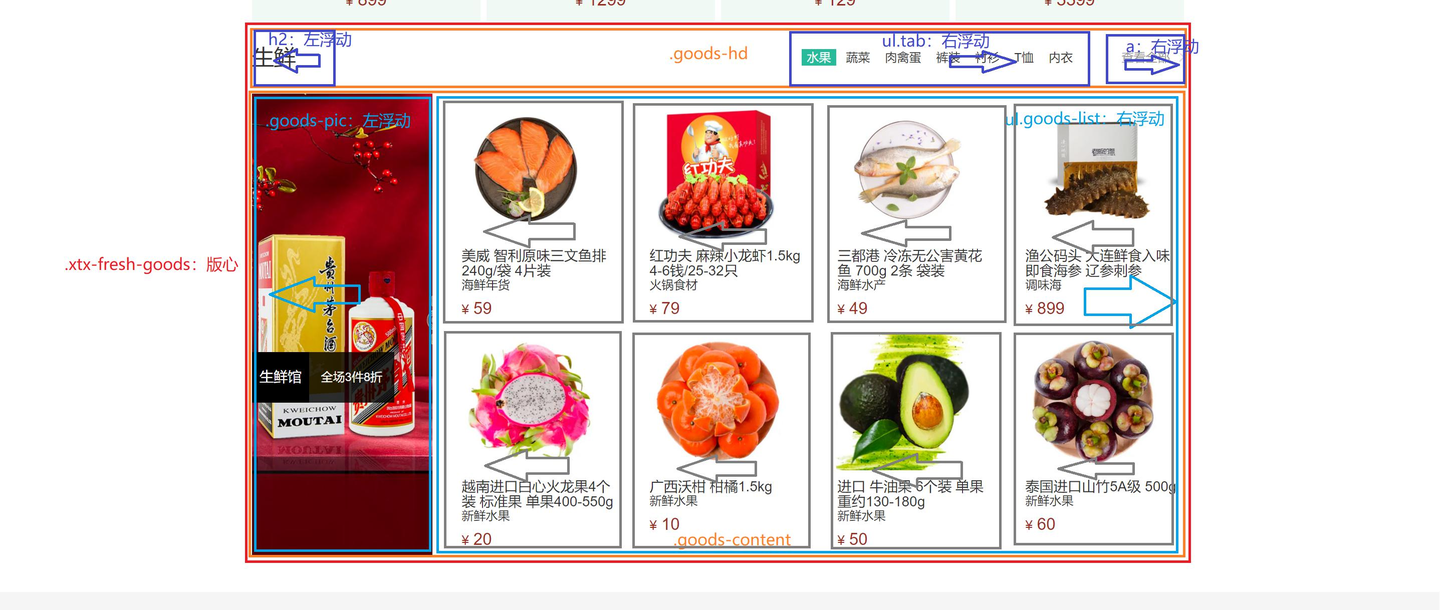

这张图的学习顺序是：先确定整个生鲜面板，再确定标题与内容，内容拆成左右两区，最后在右区划分商品项。不要一开始只摆零散图片而忽略父盒子层级。

本资料没有提供右侧八个商品项的HTML，也没有对应的图片、名称、价格布局规则；`index.css`到 `.shengxian .bd .right`就结束。`uploads`中存在 `fresh_goods_1.jpg`等素材，并不表示这些素材已经被使用。

补充：这一节保留原课的列表布局分析，不自行编造单项宽高、间距或下一阶段商品代码。用本日源码查看页面，右侧空白是这份资料的实际状态。


## 完成后核对本日页面

在项目目录中用浏览器查看 `index.html`，按本日开发顺序核对：

1. 快捷导航通栏高52px，七个入口整体靠右，最后一项显示手机图标且没有分隔边框。
2. 主导航的logo、九个栏目、搜索框和购物车在一行；链接悬停出现绿色下线，搜索文字避开放大镜，购物车显示静态数字2。
3. 页脚显示价格亲民、物流快捷、品质新鲜及不同图标，分隔线下面是两行版权文字。课件白色联系方式区在本日源码中没有实现。
4. 入口横幅按1240×500px显示，分类覆盖在左侧；左右箭头、五个圆点位于图上，第三个圆点为静态白色。源码只有一张横幅，没有切换功能。
5. 新鲜好物四张304px卡片与三段8px间距正好占满版心，前两张有新品标签。当前四张使用相同素材和商品文字。
6. 生鲜标题左侧、分类和查看全部右侧；下方240px封面与1000px空区域并排，高度610px，页脚排列在内容之后。

遇到布局问题，先检查盒子总宽度和基础重置，再检查浮动方向、父盒子高度、定位参照与精灵图坐标。入口的覆盖层使用定位，商品横向排列使用浮动；两者解决的布局问题不同。

本日源码片段按原文件连续拆分：`common.css`覆盖版心、头部与页脚全部规则，`index.css`覆盖入口、新鲜好物和生鲜已有规则，HTML片段覆盖整个 `index.html`。片段之间的未闭合标签要与相邻片段合在一起阅读，不把局部摘录当成完整页面。
